# Treinando redes neurais com TensorFlow e Keras

Continuação do notebook `atividade_tensorflow.ipynb`. Lá a rede fazia apenas o **forward pass**:

$$X \rightarrow \text{Rede} \rightarrow \hat{y} \rightarrow \text{Loss}$$

Agora vamos responder à pergunta que ficou em aberto: **como a rede aprende?**

$$\text{Loss} \rightarrow \text{Gradientes} \rightarrow \text{Backpropagation} \rightarrow \text{Gradient Descent} \rightarrow \text{Atualização dos parâmetros}$$

Roteiro:

1. Backpropagation "na mão" com `tf.GradientTape` no mesmo exemplo de 6 pedidos.
2. O efeito do **learning rate**.
3. O mesmo treinamento com Keras (`compile` + `fit`) e o otimizador **Adam**.
4. Uma **MLP** para prever atraso de pedidos reais da Olist.
5. Comparação de **funções de ativação** e **otimizadores**.
6. **Overfitting** e **regularização**: Dropout, Batch Normalization e Early Stopping.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reprodutibilidade: mesma semente em todas as bibliotecas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Backpropagation na prática com `tf.GradientTape`

Usamos os mesmos 6 pedidos da atividade anterior e a mesma arquitetura **3 → 4 → 1**.

O `GradientTape` "grava" as operações do forward pass. Depois, ele aplica a **regra da cadeia**
de trás para frente (backpropagation) e devolve o gradiente da Loss em relação a cada peso:
$\frac{\partial L}{\partial w}$.

A atualização é a **descida do gradiente**:

$$w \leftarrow w - \eta \cdot \frac{\partial L}{\partial w}$$

onde $\eta$ é o **learning rate**.

In [2]:
# Dados da atividade anterior: distância, quantidade de itens e frete (já normalizados)
X_toy = tf.constant(
    [
        [0.20, 0.10, 0.30],
        [0.80, 0.70, 0.90],
        [0.30, 0.20, 0.40],
        [0.90, 0.80, 0.70],
        [0.15, 0.30, 0.20],
        [0.75, 0.60, 0.85],
    ],
    dtype=tf.float32,
)
y_toy = tf.constant([[0], [1], [0], [1], [0], [1]], dtype=tf.float32)


def train_from_scratch(learning_rate, epochs=200, seed=SEED):
    # Parâmetros da rede 3 -> 4 -> 1, inicializados aleatoriamente
    rng = tf.random.Generator.from_seed(seed)
    W1 = tf.Variable(rng.normal((3, 4), stddev=0.5))
    b1 = tf.Variable(tf.zeros(4))
    W2 = tf.Variable(rng.normal((4, 1), stddev=0.5))
    b2 = tf.Variable(tf.zeros(1))
    params = [W1, b1, W2, b2]

    loss_fn = keras.losses.BinaryCrossentropy()
    history = []

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            # FORWARD PASS
            hidden = tf.nn.relu(X_toy @ W1 + b1)       # camada escondida + ReLU
            y_pred = tf.sigmoid(hidden @ W2 + b2)      # saída + sigmoid
            loss = loss_fn(y_toy, y_pred)              # quanto a rede errou

        # BACKPROPAGATION: gradiente da loss em relação a cada parâmetro
        gradients = tape.gradient(loss, params)

        # GRADIENT DESCENT: dá um passo na direção oposta ao gradiente
        for param, grad in zip(params, gradients):
            param.assign_sub(learning_rate * grad)

        history.append(float(loss))

    return history, y_pred


history, y_pred = train_from_scratch(learning_rate=0.5)

print(f"Loss na época 1:   {history[0]:.4f}")
print(f"Loss na época 200: {history[-1]:.4f}")
print("\nProbabilidades finais:", np.round(y_pred.numpy().ravel(), 3))
print("Valores reais:        ", y_toy.numpy().ravel().astype(int))

Loss na época 1:   0.6942
Loss na época 200: 0.0194

Probabilidades finais: [0.033 0.997 0.033 0.997 0.033 0.989]
Valores reais:         [0 1 0 1 0 1]


A loss caiu e as probabilidades se aproximaram dos valores reais: a rede **aprendeu** ajustando os
pesos a partir do próprio erro.

## 2. O efeito do learning rate

O learning rate é o **tamanho do passo**. Pequeno demais: aprende devagar. Grande demais: o passo
"pula" o mínimo e a loss oscila ou explode.

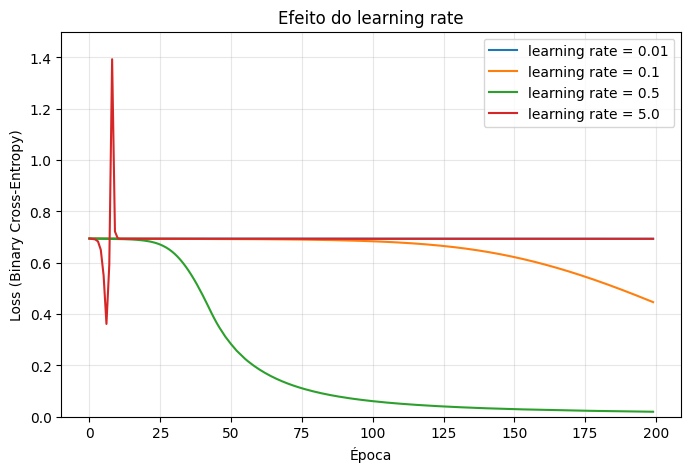

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))

for lr in [0.01, 0.1, 0.5, 5.0]:
    history, _ = train_from_scratch(learning_rate=lr)
    ax.plot(history, label=f"learning rate = {lr}")

ax.set(xlabel="Época", ylabel="Loss (Binary Cross-Entropy)", title="Efeito do learning rate")
ax.set_ylim(0, 1.5)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Leitura:**

- `0.01`: o passo é tão pequeno que a loss praticamente não sai do lugar em 200 épocas.
- `0.1`: aprende, mas devagar; ainda está caindo na época 200.
- `0.5`: converge rápido para uma loss perto de zero.
- `5.0`: o passo é grande demais. A loss **dispara** nas primeiras épocas e depois trava: os
  pesos foram empurrados para uma região em que os neurônios ReLU só devolvem zero ("neurônios
  mortos") e a rede para de aprender.

## 3. O mesmo treinamento com Keras

O `model.fit()` faz exatamente o loop acima (forward → loss → backpropagation → atualização),
em lotes (*batches*) e por várias **épocas**. O otimizador **Adam** ajusta o passo de cada peso
automaticamente usando o histórico dos gradientes, por isso costuma convergir mais rápido que a
descida do gradiente "pura" (SGD).

In [4]:
keras.utils.set_random_seed(SEED)

toy_model = keras.Sequential(
    [
        layers.Input(shape=(3,)),
        layers.Dense(4, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ]
)

toy_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.05),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

toy_history = toy_model.fit(X_toy, y_toy, epochs=200, verbose=0)

print(f"Loss final: {toy_history.history['loss'][-1]:.4f}")
print(f"Acurácia final: {toy_history.history['accuracy'][-1]:.2f}")
print("Probabilidades:", np.round(toy_model.predict(X_toy, verbose=0).ravel(), 3))

Loss final: 0.0075
Acurácia final: 1.00
Probabilidades: [0.014 1.    0.014 1.    0.014 0.999]


## 4. MLP com dados reais: risco de atraso na Olist

Agora usamos a base refinada do projeto Olist (pedidos entregues, com as features criadas lá).

Diferenças importantes em relação aos modelos de árvore do projeto Olist:

- **Escala importa:** redes neurais aprendem por gradiente, então features em escalas muito
  diferentes (preço em centenas, flags 0/1) atrapalham o treino. Usamos `StandardScaler`,
  ajustado **somente no treino** para evitar *data leakage*.
- **Categóricas** viram One-Hot (`pd.get_dummies`).
- **Desbalanceamento:** só ~8% atrasam; usamos `class_weight` para dar mais peso aos atrasos.

In [5]:
from pathlib import Path

# Base gerada pelo pipeline do projeto Olist (python -m module_olist.main)
OLIST_DATA = Path.cwd().parents[1] / "olist" / "data" / "interim" / "orders_dataset_refined.csv"

NUMERIC = [
    "promised_days", "item_count", "seller_count", "total_price", "total_freight",
    "approval_hours", "avg_item_price", "freight_ratio", "is_short_deadline",
    "is_weekend_purchase",
]
CATEGORICAL = ["purchase_month", "purchase_weekday", "purchase_hour", "customer_state"]
TARGET = "is_late"

data = pd.read_csv(OLIST_DATA)
print("Pedidos:", data.shape[0])
print("Taxa de atraso: {:.2%}".format(data[TARGET].mean()))

X = pd.get_dummies(data[NUMERIC + CATEGORICAL], columns=CATEGORICAL, dtype="float32")
y = data[TARGET].to_numpy()

# Treino (60%), validação (20%) e teste (20%), estratificados
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED
)

# Scaling: fit SOMENTE no treino
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_val = scaler.transform(X_val).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

# Peso das classes: inversamente proporcional à frequência
n_pos = y_train.sum()
n_neg = len(y_train) - n_pos
CLASS_WEIGHT = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}

print(f"Treino: {X_train.shape} | Validação: {X_val.shape} | Teste: {X_test.shape}")
print("Peso das classes:", {k: round(v, 2) for k, v in CLASS_WEIGHT.items()})

Pedidos: 96450
Taxa de atraso: 8.11%
Treino: (57870, 80) | Validação: (19290, 80) | Teste: (19290, 80)
Peso das classes: {0: np.float64(0.54), 1: np.float64(6.16)}


In [6]:
METRICS = [
    keras.metrics.AUC(curve="PR", name="pr_auc"),
    keras.metrics.AUC(curve="ROC", name="roc_auc"),
]


def build_mlp(activation="relu", optimizer="adam", hidden=(64, 32), dropout=0.0, batch_norm=False):
    # MLP: entrada -> camadas escondidas -> 1 neurônio sigmoid (probabilidade de atraso)
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([layers.Input(shape=(X_train.shape[1],))])

    for units in hidden:
        model.add(layers.Dense(units))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=METRICS)
    return model


mlp = build_mlp()
mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,297 (28.50 KB)

 Trainable params: 7,297 (28.50 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Comparando funções de ativação e otimizadores

Mesma arquitetura, trocando apenas **um** componente por vez. Avaliamos no conjunto de
**validação** (o teste fica guardado para o final).

In [7]:
def fit_and_score(model, epochs=10):
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=256,
        class_weight=CLASS_WEIGHT,
        verbose=0,
    )
    return history, history.history["val_pr_auc"][-1]


results = []

for activation in ["relu", "tanh", "sigmoid"]:
    _, score = fit_and_score(build_mlp(activation=activation))
    results.append({"experimento": f"ativação = {activation}", "val_pr_auc": score})

for name, optimizer in [
    ("SGD (lr=0.01)", keras.optimizers.SGD(learning_rate=0.01)),
    ("Adam (lr=0.001)", keras.optimizers.Adam(learning_rate=0.001)),
]:
    _, score = fit_and_score(build_mlp(optimizer=optimizer))
    results.append({"experimento": f"otimizador = {name}", "val_pr_auc": score})

pd.DataFrame(results).round(4)

,experimento,val_pr_auc
0,ativação = relu,0.2302
1,ativação = tanh,0.2186
2,ativação = sigmoid,0.2292
3,otimizador = SGD (lr=0.01),0.2110
4,otimizador = Adam (lr=0.001),0.2302


**Leitura:** a **ReLU** teve o melhor resultado, com a sigmoid logo atrás e a tanh um pouco abaixo.
A ReLU é o padrão nas camadas escondidas porque não "satura": o gradiente não some para valores
altos, como acontece com sigmoid e tanh, o que pesa mais em redes profundas. O **Adam** superou o
**SGD** com o mesmo número de épocas, porque ajusta o passo de cada peso automaticamente. A **sigmoid** continua na **saída**, porque transforma o valor
em uma probabilidade entre 0 e 1.

## 6. Overfitting e regularização

Para enxergar o overfitting com clareza, treinamos uma rede **grande** com **poucos dados**
(3.000 pedidos) por muitas épocas. Depois repetimos com regularização:

- **Dropout:** desliga neurônios aleatoriamente no treino, para a rede não depender de poucos caminhos.
- **Batch Normalization:** normaliza as ativações de cada camada e estabiliza o treino.
- **Early Stopping:** para o treino quando a validação para de melhorar e restaura os melhores pesos.

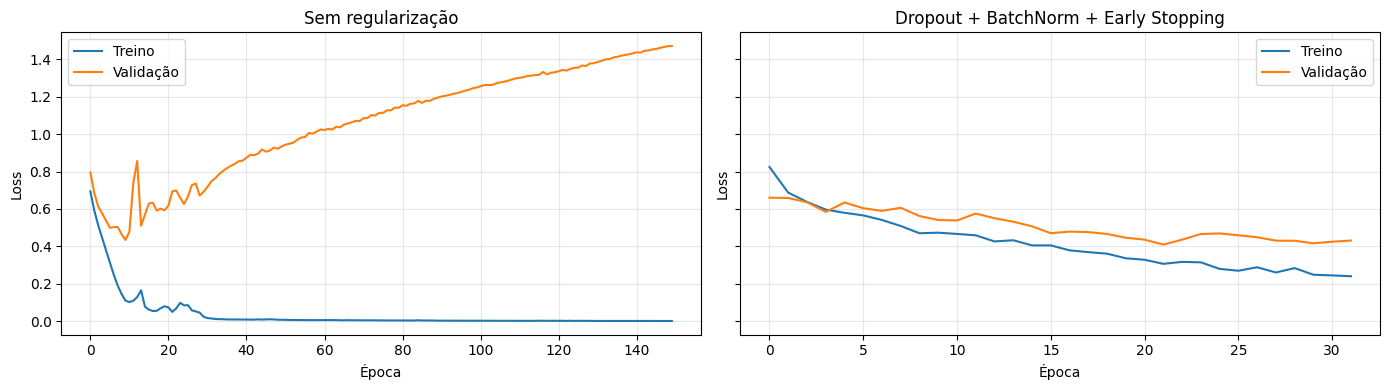

Épocas treinadas com Early Stopping: 32


In [8]:
X_small, y_small = X_train[:3000], y_train[:3000]


def train_small(model, epochs=150, callbacks=None):
    return model.fit(
        X_small, y_small,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=128,
        class_weight=CLASS_WEIGHT,
        callbacks=callbacks or [],
        verbose=0,
    )


# Sem regularização
history_overfit = train_small(build_mlp(hidden=(256, 128, 64)))

# Com Dropout + BatchNorm + Early Stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)
history_reg = train_small(
    build_mlp(hidden=(256, 128, 64), dropout=0.3, batch_norm=True),
    callbacks=[early_stopping],
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, history, title in [
    (axes[0], history_overfit, "Sem regularização"),
    (axes[1], history_reg, "Dropout + BatchNorm + Early Stopping"),
]:
    ax.plot(history.history["loss"], label="Treino")
    ax.plot(history.history["val_loss"], label="Validação")
    ax.set(xlabel="Época", ylabel="Loss", title=title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Épocas treinadas com Early Stopping:", len(history_reg.history["loss"]))

**Leitura das curvas:**

- **Sem regularização:** a loss de **treino** continua caindo, mas a de **validação** volta a
  subir. A rede está **memorizando** os 3.000 pedidos: é o overfitting.
- **Com regularização:** treino e validação ficam próximos, e o Early Stopping interrompe o
  treino antes de a validação piorar.

## 7. Modelo final e avaliação no teste

Treinamos a MLP regularizada com **todo** o conjunto de treino e avaliamos uma única vez no teste.

In [9]:
final_model = build_mlp(hidden=(128, 64), dropout=0.3, batch_norm=True)

final_history = final_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=256,
    class_weight=CLASS_WEIGHT,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True
        )
    ],
    verbose=0,
)

y_proba_test = final_model.predict(X_test, verbose=0).ravel()

print("Épocas treinadas:", len(final_history.history["loss"]))
print(f"Teste - ROC-AUC: {roc_auc_score(y_test, y_proba_test):.3f}")
print(f"Teste - PR-AUC:  {average_precision_score(y_test, y_proba_test):.3f}")
print(f"Referência (sempre 'no prazo') - PR-AUC: {y_test.mean():.3f}")

Épocas treinadas: 19
Teste - ROC-AUC: 0.752
Teste - PR-AUC:  0.235
Referência (sempre 'no prazo') - PR-AUC: 0.081


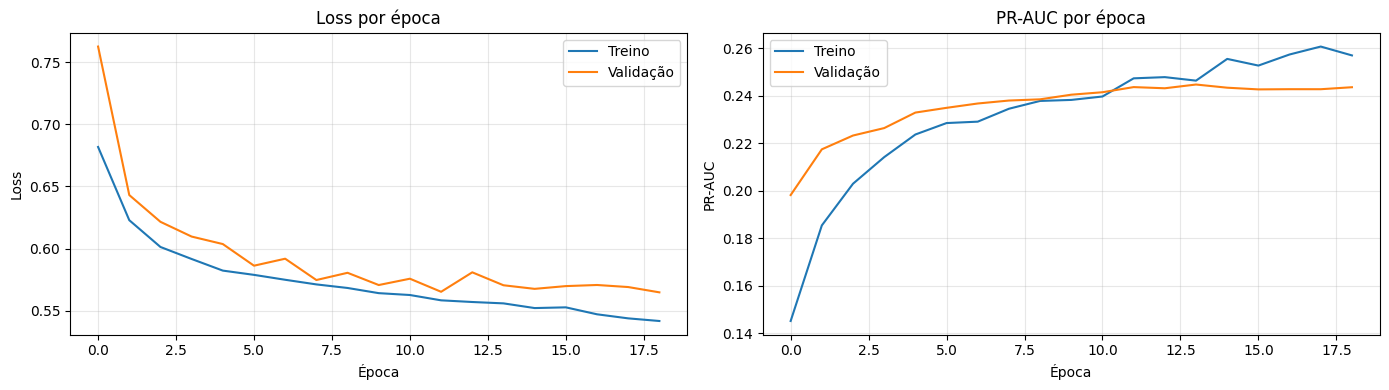

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(final_history.history["loss"], label="Treino")
axes[0].plot(final_history.history["val_loss"], label="Validação")
axes[0].set(xlabel="Época", ylabel="Loss", title="Loss por época")

axes[1].plot(final_history.history["pr_auc"], label="Treino")
axes[1].plot(final_history.history["val_pr_auc"], label="Validação")
axes[1].set(xlabel="Época", ylabel="PR-AUC", title="PR-AUC por época")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusão

- A rede aprende pelo ciclo **forward → loss → backpropagation → atualização**; o
  `GradientTape` mostra esse ciclo explicitamente e o `model.fit()` o automatiza.
- O **learning rate** controla o tamanho do passo: pequeno demais não aprende, grande demais
  diverge.
- **ReLU** nas camadas escondidas e **sigmoid** na saída é a combinação padrão para
  classificação binária; o **Adam** converge mais rápido que o SGD.
- Redes neurais exigem **scaling** das features (diferente dos modelos de árvore).
- Rede grande + poucos dados = **overfitting** (validação piora enquanto o treino melhora).
  **Dropout**, **Batch Normalization** e **Early Stopping** controlam isso.
- Em dados **tabulares** como os da Olist, a MLP (PR-AUC no teste ≈ 0,23) ficou **abaixo** do
  XGBoost do projeto Olist (≈ 0,26), além de ser mais difícil de ajustar e de explicar. Isso é
  comum: em tabelas, modelos de árvore costumam vencer. Redes neurais se destacam em dados
  **não estruturados**, como imagens, que é o próximo passo (visão computacional).